# 06 — Extra research: deeper checks of Parts 1 and 2

All analyses in this notebook are **post-hoc**: they were added on 25 Nov 2026, after the results of Parts 1 and 2 were known. The details, the predictions and the pass/fail rules were written in the plan **before** the first run (`plan/analysis_plan.md`, change log 25 Nov 2026). No new exposure is added.

| Section | Question |
|---|---|
| 3. External check | Do our BMI counts and rates agree with a published NCHS report? |
| 4. Cause of death | Does each factor act through the cause of death that biology predicts? |
| 5. Recording bias | Can errors in the birth-certificate check boxes explain the risk ratios? |
| 6. Stillbirths | Does looking only at live births hide part of the risk? |
| 7. Mediation | How much of each effect runs through earlier delivery (gestational age)? |
| 8. Decision curves | Would a program that acts on the Part 1 model do better than acting on everyone or no one? |

**Inputs.** The Parquet files of `00_data_build`, the Part 2 analysis table and functions of `04_association`, the Part 1 tables and models of `03_prediction`, and the NCHS fetal-death files 2016–2023 (`data/fetal/`, downloaded 25 Nov 2026).

**Run time.** About 1.5 hours with `REBUILD = True` (mediation bootstrap about 45 minutes, strict model refit and decision curves about 20 minutes). With `REBUILD = False` the notebook only reads the saved results.

## 1. Setup

The notebook re-uses the functions of `04_association` and `03_prediction` instead of copying them. `load_cells` runs the needed code cells of those notebooks, each in its own namespace: `p2.fit` is the modified Poisson fit of Part 2 and `p1.fit` is the model fit of Part 1. Only definitions run; the heavy stages of those notebooks do not run.

In [1]:
REBUILD = False
BOOT_MED = 200       # bootstrap replicates for the mediation CIs (E4)
BOOT_DCA = 200       # bootstrap replicates for the decision curves (E5)
N_BIAS = 10_000      # draws in the bias analysis (E2)

In [2]:
import gc
import io
import time
import zipfile
from pathlib import Path
from types import SimpleNamespace

import duckdb
import matplotlib.pyplot as plt
import nbformat
import numpy as np
import polars as pl

ROOT = Path.cwd().parent
EXTRA = ROOT / "data" / "extra"          # ignored by Git
EXTRA.mkdir(parents=True, exist_ok=True)
FETAL_ZIPS = ROOT / "data" / "fetal"
REPORTS = ROOT / "reports"
FIG = REPORTS / "figures"
SEED = 20261125
pl.Config.set_tbl_rows(80); pl.Config.set_tbl_cols(30); pl.Config.set_tbl_width_chars(220); pl.Config.set_float_precision(4)


def log(*a):
    print(time.strftime("%H:%M:%S"), *a, flush=True)


def load_cells(notebook, starts, cut=None, **preset):
    """Run selected code cells of another notebook in their own namespace and return it.

    starts: the first characters of each code cell to run, in order.
    cut: {start: text}; run that cell only up to `text` (its definitions, not its heavy work).
    The namespace keeps the two notebooks' names apart (both define `fit`, `WORK`, ...).
    """
    ns = {"__name__": Path(notebook).stem, **preset}
    cells = [c for c in nbformat.read(notebook, 4).cells if c.cell_type == "code"]
    for s in starts:
        src = [c.source for c in cells if c.source.startswith(s)]
        assert len(src) == 1, f"{notebook}: {len(src)} cells start with {s!r}"
        src = src[0]
        if cut and s in cut:
            assert cut[s] in src
            src = src.split(cut[s])[0]
        exec(compile(src, f"{notebook}: {s}", "exec"), ns)
    return SimpleNamespace(**ns)


# Part 2 tools: modified Poisson, analysis table, exposures, pooling, multinomial fit
p2 = load_cells("04_association.ipynb",
                ["import gc", "def design", "GEST_M", "REF =", "def fit_model", "def evalue", "from scipy.optimize"],
                cut={"def evalue": "\ngood = fits", "from scipy.optimize": "\ndef collapse"},
                REBUILD=False, MI_M=20, MI_TEST=False)
# Part 1 tools: inputs, metrics, models
p1 = load_cells("03_prediction.ipynb", ["import gc", "@dataclass", "class SortedScores", "SETS ="], REBUILD=False)
log("loaded tools from 04_association and 03_prediction")

fits: 752 | failed: 0 | largest predicted risk: 1.2276


12:36:54 loaded tools from 04_association and 03_prediction


## 2. Data

### 2.1 Analysis table with the cause of death

**What.** The Part 2 analysis table (resident singletons, same item codes as `04_association` section 5) with two more columns:
- `cause`: the cause-of-death group of each infant death, from the 130-cause recode `UCODR130` (codes from the CDC user guide);
- `parp`: parity as earlier live births + 1. The fetal-death file has no live birth order of the same kind, so section 6 uses this definition on both files.

| Group | `UCODR130` codes | ICD-10 |
|---|---|---|
| preterm / low birth weight | 088–090 | P07 |
| maternal / placental | 071–085 | P00–P04 |
| congenital anomalies | 118–133 | Q00–Q99 |
| SUID (sudden unexpected infant death) | 135, 136, 146 | R95, other ill-defined R codes, W75 |
| infection | 001–022, 040, 054–058, 105–108 | A00–B99, G00/G03, J00–J18, P35–P39 |
| other | all other codes | |

In [3]:
CAUSES = {1: "preterm / low birth weight", 2: "maternal / placental", 3: "congenital anomalies",
          4: "SUID", 5: "infection", 6: "other"}
CAUSE_SQL = """CASE WHEN NOT death THEN 0
    WHEN UCODR130 BETWEEN '088' AND '090' THEN 1
    WHEN UCODR130 BETWEEN '071' AND '085' THEN 2
    WHEN UCODR130 BETWEEN '118' AND '133' THEN 3
    WHEN UCODR130 IN ('135', '136', '146') THEN 4
    WHEN UCODR130 BETWEEN '001' AND '022' OR UCODR130 = '040' OR UCODR130 BETWEEN '054' AND '058'
         OR UCODR130 BETWEEN '105' AND '108' THEN 5
    ELSE 6 END"""
# parity from the counts of earlier live births; the fetal-death file uses the same items
PARP_SQL = """CASE WHEN PRIORLIVE IS NULL OR PRIORDEAD IS NULL OR PRIORLIVE = '99' OR PRIORDEAD = '99' THEN NULL
    ELSE least(CAST(PRIORLIVE AS INT) + CAST(PRIORDEAD AS INT) + 1, 4) END"""
BIRTHS_X = EXTRA / "births_extra.parquet"
X_COLS = ["age", "race", "nat", "edu", "pay", "par", "smoke", "bmi", "htn", "dm", "ppb", "priorloss", "priordead",
          "ilp_status", "ipi", "ga", "d1", "dneo", "dpost", "dacc"]
if REBUILD or not BIRTHS_X.exists():
    q = p2.DERIVED.replace("\nFROM read_parquet", f",\n  {CAUSE_SQL} AS cause,\n  {PARP_SQL} AS parp\nFROM read_parquet", 1)
    assert "AS parp" in q
    con = duckdb.connect()
    con.sql("SET threads TO 4")
    cast = ", ".join(f"CAST({c} AS TINYINT) AS {c}" for c in X_COLS + ["cause", "parp"])
    con.sql(f"COPY (SELECT CAST(cohort AS SMALLINT) AS cohort, {cast} FROM ({q})) TO '{BIRTHS_X}' (FORMAT parquet)")
    con.close()
    log("built", BIRTHS_X.name)
cause_counts = duckdb.sql(f"""SELECT cause, COUNT(*) AS deaths, SUM(dneo)::BIGINT AS neonatal, SUM(dpost)::BIGINT AS postneonatal
                              FROM '{BIRTHS_X}' WHERE d1 = 1 GROUP BY cause ORDER BY cause""").pl()
cause_counts = cause_counts.with_columns(group=pl.col("cause").replace_strict(CAUSES), share=pl.col("deaths") / pl.col("deaths").sum())
cause_counts.write_csv(REPORTS / "extra_cause_counts.csv")
cause_counts

cause,deaths,neonatal,postneonatal,group,share
i8,i64,i64,i64,str,f64
1,20671,20167,504,"""preterm / low birth weight""",0.1431
2,14313,14073,240,"""maternal / placental""",0.0991
3,31686,22517,9169,"""congenital anomalies""",0.2193
4,26481,3226,23255,"""SUID""",0.1833
5,10292,5142,5150,"""infection""",0.0712
6,41058,26556,14502,"""other""",0.2841


**Result.** 144,501 infant deaths among resident singletons have a cause group. The largest groups are "other" (28%), congenital anomalies (22%), SUID (18%) and preterm / low birth weight (14%). SUID deaths are mostly postneonatal (23,255 of 26,481); preterm / low birth weight deaths are almost all neonatal.

### 2.2 Fetal deaths (stillbirths)

**What.** The NCHS public fetal-death files 2016–2023 are fixed-width text, 3,050 (2016–2017) or 3,150 (2018–2023) characters per record. The field positions come from the NCHS user guides (`docs/fetal_guides/`); they are the same in all 8 years. We read 20 fields.

In [4]:
# Positions (1-based, from the NCHS fetal-death user guides 2016-2023; identical in all 8 years)
FETAL_FIELDS = {"DOD_YY": (11, 4), "MAGER9": (90, 1), "MBSTATE_REC": (97, 1), "RESTATUS": (131, 1),
                "SR_MRACEHISP": (144, 1), "MEDUC": (145, 1), "PRIORLIVE": (181, 2), "PRIORDEAD": (183, 2),
                "CIG_0": (230, 2), "BMI_R": (249, 1), "RF_DIAB": (257, 1), "RF_PHYP": (259, 1), "DPLURAL": (301, 1),
                "COMBGEST": (331, 2), "F_MEDUC": (372, 1), "F_M_HT": (375, 1), "F_PWGT": (376, 1),
                "F_RF_PDIAB": (378, 1), "F_RF_PHYPER": (380, 1), "F_CIGS_0": (405, 1)}
FETAL_RAW = EXTRA / "fetal_raw.parquet"
if REBUILD or not FETAL_RAW.exists():
    parts = []
    for year in range(2016, 2024):
        with zipfile.ZipFile(FETAL_ZIPS / f"Fetal{year}US_COD.zip") as z:
            (name,) = z.namelist()
            lines = io.TextIOWrapper(z.open(name), encoding="latin-1").read().splitlines()
        cols = {f: [ln[p - 1:p - 1 + w].strip() or None for ln in lines] for f, (p, w) in FETAL_FIELDS.items()}
        df = pl.DataFrame(cols)
        assert (df["DOD_YY"] == str(year)).all(), year
        parts.append(df)
        log(year, f"{df.height:,} fetal-death records")
    pl.concat(parts).write_parquet(FETAL_RAW)
    del parts, lines, cols
fetal_raw = pl.read_parquet(FETAL_RAW)
fetal_raw.group_by("DOD_YY").agg(records=pl.len(),
                                  ge20wk=(pl.col("COMBGEST").cast(pl.Int32, strict=False).is_between(20, 47)).sum()).sort("DOD_YY")

DOD_YY,records,ge20wk
str,u32,u32
"""2016""",51391,23861
"""2017""",49170,22897
"""2018""",47676,22500
"""2019""",46007,21501
"""2020""",41816,20958
"""2021""",42428,21153
"""2022""",40113,20288
"""2023""",39574,20007


**Result.** 358,175 fetal-death records in 8 files. Some states also report fetal deaths before 20 weeks; with a stated gestation of 20–47 weeks there are 23,861 (2016) to 20,007 (2023) fetal deaths. The number falls every year.

### 2.3 Fetal deaths in the Part 2 coding

**What.** Resident (`RESTATUS` < 4) singleton fetal deaths at 20 weeks or more (`COMBGEST`), with the same category codes as the live births. A reporting flag other than 1 means "item not reported by the state" and becomes missing, as for the live births. The table compares the share of missing values in the two files.

In [5]:
def fyn(col, flag):
    return pl.when(pl.col(flag).fill_null("1") != "1").then(None).when(pl.col(col) == "Y").then(1).when(pl.col(col) == "N").then(0)


def fint(col):
    return pl.col(col).cast(pl.Int32, strict=False)


fetal = fetal_raw.filter((fint("RESTATUS") < 4) & (pl.col("DPLURAL") == "1") & fint("COMBGEST").is_between(20, 47)).select(
    cohort=fint("DOD_YY").cast(pl.Int16),
    age=pl.col("MAGER9").replace_strict({"1": 1, "2": 1, "3": 2, "4": 3, "5": 4, "6": 5, "7": 6, "8": 6, "9": 6}, default=None),
    race=pl.when(fint("SR_MRACEHISP").is_between(1, 7)).then(fint("SR_MRACEHISP")),
    nat=pl.col("MBSTATE_REC").replace_strict({"1": 1, "2": 2}, default=None),
    edu=pl.when(pl.col("F_MEDUC").fill_null("1") != "1").then(None)
          .otherwise(pl.col("MEDUC").replace_strict({"1": 1, "2": 1, "3": 2, "4": 3, "5": 3, "6": 4, "7": 5, "8": 5}, default=None)),
    parp=pl.when(fint("PRIORLIVE").is_between(0, 98) & fint("PRIORDEAD").is_between(0, 98))
           .then(pl.min_horizontal(fint("PRIORLIVE") + fint("PRIORDEAD") + 1, pl.lit(4))),
    smoke=pl.when((pl.col("F_CIGS_0").fill_null("1") != "1") | ~fint("CIG_0").is_between(0, 98)).then(None)
            .when(fint("CIG_0") == 0).then(0).otherwise(1),
    bmi=pl.when((pl.col("F_PWGT").fill_null("1") != "1") | (pl.col("F_M_HT").fill_null("1") != "1")).then(None)
          .when(fint("BMI_R").is_between(1, 6)).then(fint("BMI_R")),
    htn=fyn("RF_PHYP", "F_RF_PHYPER"),
    dm=fyn("RF_DIAB", "F_RF_PDIAB"),
).with_columns(pl.exclude("cohort").cast(pl.Int8))
fetal_missing = fetal.select(pl.exclude("cohort").null_count() / fetal.height)
births_missing = duckdb.sql(f"""SELECT {", ".join(f"AVG(({c} IS NULL)::INT) AS {c}" for c in ["age", "race", "nat", "edu", "parp", "smoke", "bmi", "htn", "dm"])}
                                FROM '{BIRTHS_X}'""").pl()
log(f"{fetal.height:,} resident singleton fetal deaths at >= 20 weeks, 2016-2023")
pl.concat([births_missing.with_columns(file=pl.lit("live births")), fetal_missing.with_columns(file=pl.lit("fetal deaths"))],
          how="diagonal_relaxed").select("file", "age", "race", "nat", "edu", "parp", "smoke", "bmi", "htn", "dm")

12:36:54 159,494 resident singleton fetal deaths at >= 20 weeks, 2016-2023


file,age,race,nat,edu,parp,smoke,bmi,htn,dm
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""live births""",0.0000,0.0091,0.0021,0.0191,0.0029,0.0091,0.0272,0.0058,0.0058
"""fetal deaths""",0.0000,0.0481,0.0635,0.1474,0.0595,0.0967,0.1473,0.0762,0.0762


**Result.** 159,494 resident singleton fetal deaths at ≥ 20 weeks. **The fetal-death records miss much more information** than the birth records: education and BMI 14.7% (births 1.9% and 2.7%), smoking 9.7% (0.9%), hypertension and diabetes 7.6% (0.6%). One known reason: in 2016, Connecticut and New York did not yet use the revised fetal-death report, so their records have no risk-factor items (reporting flag 0 for 8,145 of 51,391 records). Section 6 uses complete cases; this is a limitation of that section.

## 3. External check: BMI against NVSR 69(9)

**Why.** Every earlier check compared our data with CDC tables of the same files. This check uses an independent publication: Ely, Gregory and Drake, *Infant mortality by maternal prepregnancy body mass index: United States, 2017–2018*, National Vital Statistics Reports 69(9), 2020, Table 2 (PDF in `docs/external/`).

**What.** All resident births of the 2017 and 2018 cohorts, by BMI class (no other filter, as in the report). The report uses the *period* files (deaths in 2017–2018), we use the *cohort* files (deaths of babies born in 2017–2018). The births must be the same; the death rates can differ a little.

**Rule (fixed before the run).** PASS if the births of each class agree within 0.5% and the rates within 5%.

In [6]:
# NVSR 69(9), Table 2 (Ely, Gregory, Drake 2020): 2017-2018 period linked files, all births
NVSR = pl.DataFrame({"class": ["underweight", "normal", "overweight", "obese"],
                     "nvsr_births": [244_734, 3_189_241, 1_972_220, 2_058_054],
                     "nvsr_rate": [5.84, 4.57, 5.16, 7.07]})
ours = duckdb.sql(f"""
    SELECT CASE WHEN BMI_R = '1' THEN 'underweight' WHEN BMI_R = '2' THEN 'normal' WHEN BMI_R = '3' THEN 'overweight'
                WHEN BMI_R IN ('4', '5', '6') THEN 'obese' END AS class,
           COUNT(*) AS our_births, 1000 * AVG(death::INT) AS our_rate
    FROM read_parquet('{p2.PARQUET}/cohort_201[78].parquet', union_by_name = true)
    WHERE CAST(RESTATUS AS INT) < 4 GROUP BY 1""").pl()
ext = NVSR.join(ours, on="class").with_columns(
    births_diff_pct=100 * (pl.col("our_births") / pl.col("nvsr_births") - 1),
    rate_diff_pct=100 * (pl.col("our_rate") / pl.col("nvsr_rate") - 1))
ext = ext.with_columns(result=pl.when((pl.col("births_diff_pct").abs() <= 0.5) & (pl.col("rate_diff_pct").abs() <= 5))
                       .then(pl.lit("PASS")).otherwise(pl.lit("FAIL")))
ext.write_csv(REPORTS / "extra_external_bmi.csv")
ext

class,nvsr_births,nvsr_rate,our_births,our_rate,births_diff_pct,rate_diff_pct,result
str,i64,f64,i64,f64,f64,f64,str
"""overweight""",1972220,5.1600,1972220,5.1049,0.0000,-1.0677,"""PASS"""
"""underweight""",244734,5.8400,244734,5.8758,0.0000,0.6125,"""PASS"""
"""obese""",2058054,7.0700,2058054,7.0295,0.0000,-0.5735,"""PASS"""
"""normal""",3189241,4.5700,3189241,4.5403,0.0000,-0.6507,"""PASS"""


**Result. PASS.** The number of births in each BMI class is **identical** to NVSR 69(9) (difference 0 in all four classes). So our BMI coding and population are the same as NCHS's. The infant death rates differ by at most 1.1%, as expected from cohort vs period deaths.

## 4. Cause of death: does each factor act where biology predicts?

**Why.** The Part 2 risk ratios cover all causes together. If a factor is truly causal, its effect should be strongest for the causes that its biology predicts. A confounder such as poverty would raise all causes more evenly. This is a test that can fail.

**Predictions (fixed before the run).**
1. Diabetes: the RR is higher for **congenital anomalies** than for all other causes together (high blood sugar in early pregnancy causes birth defects).
2. Hypertension: the RR is higher for **preterm / low birth weight** than for all other causes together.
3. Smoking: the RR is higher for **SUID** than for all other causes together.

**Method.** For each exposure and each cause group, one modified Poisson model on all 8 cohorts with cohort as a covariate, the same confounders as Part 2, and the small race classes merged (as for the negative control, because some causes are rare). For a prediction, the *ratio* of the two RRs (the predicted cause vs all other causes) is tested. Both models use the same births, so their estimates are correlated; the variance of the ratio comes from the stacked sandwich of the two models.

**Rule.** A prediction HOLDS if the ratio is above 1 and its 95% CI excludes 1.

In [7]:
PREDICTIONS = [("diabetes", 1, 3), ("hypertension", 1, 1), ("smoking", 1, 4)]   # (exposure, class, cause)


def cause_patterns(e):
    """Pattern counts over all cohorts: births and deaths per cause group; small race classes merged."""
    cols = [e.col] + e.confounders
    keep = " AND ".join(f"{c} IS NOT NULL" for c in cols)
    sums = ", ".join(f"SUM((cause = {k})::INT)::BIGINT AS c{k}" for k in CAUSES)
    race = "CASE WHEN race IN (3, 5, 6) THEN 9 ELSE race END AS race"
    sel = ", ".join(race if c == "race" else c for c in cols)
    q = f"""SELECT cohort, {sel}, COUNT(*) AS n, SUM(d1)::BIGINT AS d1, {sums}
            FROM '{BIRTHS_X}' WHERE {e.where} AND {keep} GROUP BY ALL"""
    return duckdb.sql(q).pl()


def ratio_of_rrs(X, n, d_a, d_b, j):
    """log RR of column j for outcome a and for outcome b (same births, outcomes exclusive),
    and the variance of their difference from the stacked sandwich of the two models."""
    ra, rb = p2.fit(X, n, d_a), p2.fit(X, n, d_b)
    mu_a, mu_b = np.exp(X @ ra["beta"]), np.exp(X @ rb["beta"])
    # sum over births of (y_a - mu_a)(y_b - mu_b): y_a = 1, y_b = 1 and neither
    w = d_a * (1 - mu_a) * (-mu_b) + d_b * (-mu_a) * (1 - mu_b) + (n - d_a - d_b) * mu_a * mu_b
    cov_ab = ra["cov_model"] @ ((X * w[:, None]).T @ X) @ rb["cov_model"]
    va, vb = ra["cov_robust"][j, j], rb["cov_robust"][j, j]
    return ra["beta"][j], rb["beta"][j], va, vb, va + vb - 2 * cov_ab[j, j]


CAUSE_FILE = REPORTS / "extra_cause_specific.csv"
RATIO_FILE = REPORTS / "extra_cause_predictions.csv"
if REBUILD or not CAUSE_FILE.exists():
    rows, ratios = [], []
    for e in p2.EXPOSURES:
        g = cause_patterns(e)
        cols = [e.col] + e.confounders + ["cohort"]
        X, names = p2.design({c: g[c].to_numpy() for c in cols}, cols, {**p2.REF, "race": 1})
        n = g["n"].to_numpy().astype(np.float64)
        for k, cause in CAUSES.items():
            res = p2.fit(X, n, g[f"c{k}"].to_numpy())
            for cls, label in e.labels.items():
                r = p2.rr(res, names, f"{e.col}={cls}")
                rows.append({"exposure": e.name, "label": label, "cause": cause,
                             "deaths_exposed": int(g.filter(pl.col(e.col) == cls)[f"c{k}"].sum()),
                             **{key: r[key] for key in ("rr", "rr_lo", "rr_hi", "log_rr", "se")}})
        for name, cls, k in PREDICTIONS:
            if name != e.name:
                continue
            d_k = g[f"c{k}"].to_numpy().astype(np.float64)
            d_rest = g["d1"].to_numpy() - d_k
            j = names.index(f"{e.col}={cls}")
            ba, bb, va, vb, vd = ratio_of_rrs(X, n, d_k, d_rest, j)
            ratios.append({"exposure": e.name, "label": e.labels[cls], "cause": CAUSES[k],
                           "rr_cause": np.exp(ba), "rr_other_causes": np.exp(bb), "ratio": np.exp(ba - bb),
                           "ratio_lo": np.exp(ba - bb - 1.96 * np.sqrt(vd)), "ratio_hi": np.exp(ba - bb + 1.96 * np.sqrt(vd)),
                           "corr_log_rr": float((va + vb - vd) / 2 / np.sqrt(va * vb))})
        log("cause-specific", e.name)
        del g, X
        gc.collect()
    pl.DataFrame(rows).write_csv(CAUSE_FILE)
    ratio = pl.DataFrame(ratios).with_columns(
        prediction=pl.when((pl.col("ratio") > 1) & (pl.col("ratio_lo") > 1)).then(pl.lit("HOLDS")).otherwise(pl.lit("FAILS")))
    ratio.write_csv(RATIO_FILE)
cs = pl.read_csv(CAUSE_FILE)
ratio = pl.read_csv(RATIO_FILE)
ratio

exposure,label,cause,rr_cause,rr_other_causes,ratio,ratio_lo,ratio_hi,corr_log_rr,prediction
str,str,str,f64,f64,f64,f64,f64,f64,str
"""hypertension""","""yes""","""preterm / low birth weight""",1.4291,1.5037,0.9504,0.8793,1.0272,-0.0037,"""FAILS"""
"""diabetes""","""yes""","""congenital anomalies""",2.5863,1.6402,1.5768,1.4525,1.7117,-0.0051,"""HOLDS"""
"""smoking""","""any""","""SUID""",2.5123,1.3994,1.7953,1.7283,1.8648,-0.0041,"""HOLDS"""


**Result. Two of three predictions HOLD; one FAILS.**
- **Diabetes → congenital anomalies: HOLDS.** RR 2.59 for anomalies vs 1.64 for all other causes; ratio 1.58 (1.45–1.71).
- **Smoking → SUID: HOLDS.** RR 2.51 for SUID vs 1.40 for all other causes; ratio 1.80 (1.73–1.86).
- **Hypertension → preterm / low birth weight: FAILS.** RR 1.43 for this group vs 1.50 for all other causes; ratio 0.95 (0.88–1.03).

The two predictions that hold are specific: they point to the cause that each factor's biology predicts, which a social confounder would not do. Possible reason for the failure (post-hoc, not tested): the code P07 is narrow. A very preterm baby often dies of a complication that is coded elsewhere (respiratory distress, sepsis, necrotizing enterocolitis), and hypertension is strongest for infection (1.93) and "other" (1.79). Section 7 suggests that most of the hypertension effect runs through earlier delivery (an upper bound, section 9), so the mechanism is probably preterm birth even though the P07 group does not show it.

**All exposures and all cause groups** (RR and 95% CI; descriptive, no test).

In [8]:
wide = cs.with_columns(txt=pl.format("{} ({}-{})", pl.col("rr").round(2), pl.col("rr_lo").round(2), pl.col("rr_hi").round(2))) \
         .pivot(on="cause", index=["exposure", "label"], values="txt")
wide

exposure,label,preterm / low birth weight,maternal / placental,congenital anomalies,SUID,infection,other
str,str,str,str,str,str,str,str
"""hypertension""","""yes""","""1.43 (1.33-1.54)""","""1.26 (1.15-1.38)""","""1.34 (1.25-1.42)""","""1.26 (1.17-1.35)""","""1.93 (1.76-2.12)""","""1.79 (1.71-1.88)"""
"""diabetes""","""yes""","""1.44 (1.3-1.6)""","""1.48 (1.3-1.69)""","""2.59 (2.41-2.77)""","""1.29 (1.16-1.43)""","""1.94 (1.7-2.23)""","""1.94 (1.81-2.08)"""
"""bmi""","""<18.5""","""1.28 (1.17-1.4)""","""1.28 (1.15-1.42)""","""1.09 (1.02-1.17)""","""1.03 (0.97-1.11)""","""1.18 (1.06-1.32)""","""1.14 (1.08-1.21)"""
"""bmi""","""25-29.9""","""1.24 (1.19-1.3)""","""1.15 (1.1-1.21)""","""1.03 (1.0-1.06)""","""1.01 (0.98-1.04)""","""1.05 (0.99-1.1)""","""1.09 (1.06-1.12)"""
"""bmi""","""30-34.9""","""1.6 (1.53-1.67)""","""1.37 (1.29-1.44)""","""1.06 (1.03-1.1)""","""1.1 (1.06-1.14)""","""1.18 (1.11-1.25)""","""1.26 (1.22-1.3)"""
"""bmi""","""35-39.9""","""1.9 (1.8-2.01)""","""1.69 (1.59-1.81)""","""1.13 (1.08-1.18)""","""1.2 (1.15-1.26)""","""1.27 (1.18-1.37)""","""1.38 (1.33-1.43)"""
"""bmi""",""">=40""","""2.23 (2.11-2.36)""","""1.91 (1.79-2.05)""","""1.24 (1.18-1.3)""","""1.4 (1.34-1.47)""","""1.4 (1.3-1.52)""","""1.51 (1.45-1.57)"""
"""smoking""","""any""","""1.5 (1.43-1.58)""","""1.76 (1.66-1.87)""","""1.03 (0.99-1.08)""","""2.51 (2.43-2.59)""","""1.56 (1.46-1.66)""","""1.51 (1.46-1.56)"""
"""interval""","""<6 mo""","""1.39 (1.26-1.52)""","""1.12 (1.0-1.24)""","""1.0 (0.94-1.06)""","""1.32 (1.24-1.41)""","""1.36 (1.21-1.53)""","""1.23 (1.16-1.3)"""


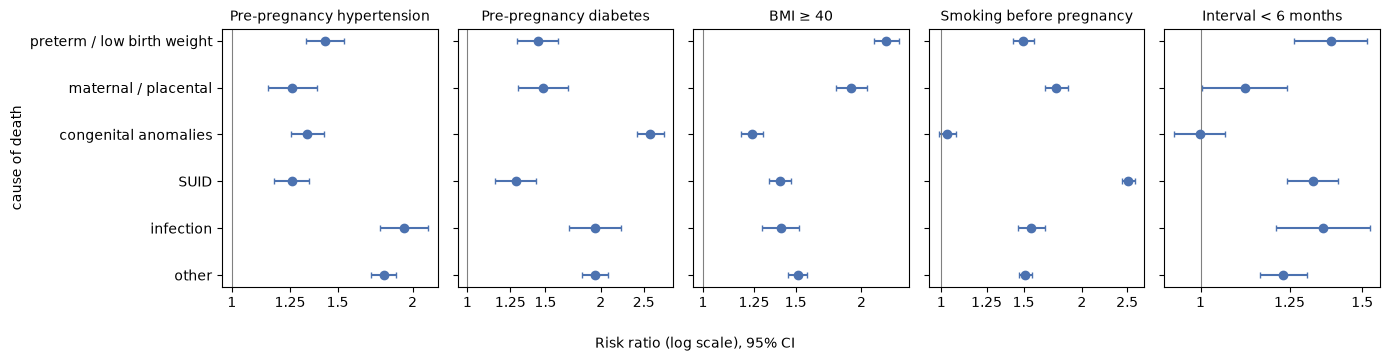

In [9]:
order = list(CAUSES.values())
PANEL_TITLE = {("hypertension", "yes"): "Pre-pregnancy hypertension", ("diabetes", "yes"): "Pre-pregnancy diabetes",
               ("bmi", ">=40"): "BMI ≥ 40", ("smoking", "any"): "Smoking before pregnancy",
               ("interval", "<6 mo"): "Interval < 6 months"}
show = cs.filter(pl.col("label").is_in(["yes", "any", ">=40", "<6 mo"]))
fig, axes = plt.subplots(1, show["exposure"].n_unique(), figsize=(14, 3.6), sharey=True)
for ax, (key, d) in zip(axes, show.group_by(["exposure", "label"], maintain_order=True)):
    d = d.with_columns(pos=pl.col("cause").replace_strict({c: i for i, c in enumerate(order)})).sort("pos")
    y = d["pos"].to_numpy()
    ax.errorbar(d["rr"], y, xerr=[d["rr"] - d["rr_lo"], d["rr_hi"] - d["rr"]], fmt="o", color="#4C72B0", capsize=2)
    ax.axvline(1, color="grey", lw=0.8)
    ax.set_xscale("log"); ax.set_title(PANEL_TITLE[key], fontsize=10)
    lo, hi = ax.get_xlim()
    ax.set_xticks([t for t in (0.8, 0.9, 1, 1.25, 1.5, 2, 2.5, 3) if lo <= t <= hi])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}")); ax.minorticks_off()
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
    ax.invert_yaxis()
axes[0].set_ylabel("cause of death")
fig.supxlabel("Risk ratio (log scale), 95% CI", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "extra_cause_specific.png", dpi=150); plt.show()

**Result.**
- **Diabetes** raises every cause (RR 1.3–1.9), but anomalies most (2.59).
- **Smoking** has no link with anomalies (1.03, CI includes 1) and its strongest link with SUID (2.51).
- **BMI ≥ 40** is strongest for preterm / low birth weight (2.23) and maternal / placental causes (1.91); weakest for anomalies (1.24).
- **Interval:** short intervals raise preterm, SUID and infection deaths, not anomalies. Intervals ≥ 60 months raise preterm deaths (1.26) but lower SUID (0.86).

## 5. Recording bias: probabilistic bias analysis

**Why.** Hypertension, diabetes and smoking come from check boxes on the birth certificate. Validation studies that compare the certificate with the medical record show that many true cases are not ticked (low *sensitivity*). This section shows how much the RRs could change because of these errors.

**Inputs (sources checked on 25 Nov 2026).**

| Item | Sensitivity (Se) | Specificity (Sp) | Source |
|---|---|---|---|
| Pre-pregnancy hypertension | Beta(14, 21), mean 0.40 | Beta(995, 5), mean 0.995 | Se: Martin et al. 2013, NVSR 62(2), Table 4, state A: 13 of 33 medical-record cases ticked. Sp: assumption (not reported) |
| Pre-pregnancy diabetes | Beta(7, 3), mean 0.70 | Beta(1998, 2), mean 0.999 | **Assumption.** No validation value for pre-pregnancy diabetes was found (Martin 2013 and Dietz et al. 2015 report only gestational or combined diabetes) |
| Smoking before pregnancy | Beta(124, 66), mean 0.65 | Beta(831, 20), mean 0.977 | Howland et al. 2015, Matern Child Health J 19:1916, Table 2 (NYC + Vermont, 2009): 123 of 188 and 830 of 849 |

**Method** (Lash, Fox and Fink, *Applying Quantitative Bias Analysis to Epidemiologic Data*). For each of 10,000 draws of Se and Sp:
1. Correct the number of exposed deaths and exposed survivors in each cohort: true exposed = (observed exposed − (1 − Sp) × all) / (Se + Sp − 1).
2. Compute the corrected crude RR (Mantel–Haenszel over cohorts).
3. Multiply by the confounding ratio (adjusted RR / crude RR of the observed data), to keep the adjustment for confounders.
4. *Total error:* add the random error of the main estimate.

Draws that give a negative corrected count are dropped and counted. Two scenarios: **non-differential** (the same Se for deaths and survivors) and **differential** (Se 10 points higher among deaths, for example because the records of sick babies are checked more carefully). The differential scenario is the one that can make the observed RR too high.

**Rule.** The claim is FRAGILE if the 95% simulation interval (total error) includes 1.

In [10]:
# Beta priors (a, b) for sensitivity and specificity; source in the last field
PRIORS = {
    "hypertension": {"se": (14, 21), "sp": (995, 5), "source": "Se: Martin et al. 2013, NVSR 62(2), Table 4, state A, 13/33; Sp: assumption"},
    "diabetes": {"se": (7, 3), "sp": (1998, 2), "source": "Se and Sp: assumptions (no validation value found for pre-pregnancy diabetes)"},
    "smoking": {"se": (124, 66), "sp": (831, 20), "source": "Howland et al. 2015, Matern Child Health J 19:1916, Table 2 (123/188, 830/849)"},
}
SE_SHIFT_DEATHS = 0.10     # differential scenario: sensitivity among deaths is 10 points higher
main = pl.read_csv(REPORTS / "part2_results.csv").filter(pl.col("outcome") == "infant")


def mh_rr(a, n1, c, n0):
    """Mantel-Haenszel RR over cohorts; arrays (..., cohorts)."""
    n = n1 + n0
    return np.sum(a * n0 / n, axis=-1) / np.sum(c * n1 / n, axis=-1)


BIAS_FILE = REPORTS / "extra_bias_analysis.csv"
if REBUILD or not BIAS_FILE.exists():
    rng = np.random.default_rng(SEED)
    rows = []
    for e in [x for x in p2.EXPOSURES if x.name in PRIORS]:
        g = p2.patterns(e).group_by(["cohort", e.col]).agg(pl.col("n", "d1").sum()).sort("cohort", e.col)
        ex, un = g.filter(pl.col(e.col) == 1), g.filter(pl.col(e.col) == 0)
        a, n1 = ex["d1"].to_numpy().astype(float), ex["n"].to_numpy().astype(float)
        c, n0 = un["d1"].to_numpy().astype(float), un["n"].to_numpy().astype(float)
        crude = mh_rr(a, n1, c, n0)
        m = main.filter(pl.col("exposure") == e.name).row(0, named=True)
        conf_ratio = m["rr"] / crude                     # adjusted RR / crude RR, same births
        se_rand = (np.log(m["rr_hi"]) - np.log(m["rr_lo"])) / 3.92
        pr = PRIORS[e.name]
        se = rng.beta(*pr["se"], N_BIAS)[:, None]
        sp = rng.beta(*pr["sp"], N_BIAS)[:, None]
        z = rng.standard_normal(N_BIAS)
        D, S = a + c, (n1 - a) + (n0 - c)               # deaths and survivors per cohort
        for scen, se_d in (("non-differential", se), ("differential (Se deaths +0.10)", np.minimum(se + SE_SHIFT_DEATHS, 0.999))):
            A = (a - (1 - sp) * D) / (se_d + sp - 1)       # corrected exposed deaths
            B = ((n1 - a) - (1 - sp) * S) / (se + sp - 1)  # corrected exposed survivors
            ok = np.all((A > 0) & (A < D) & (B > 0) & (B < S), axis=1)
            rr_sys = mh_rr(A, A + B, D - A, (D - A) + (S - B)) * conf_ratio
            rr_tot = np.exp(np.log(rr_sys) - z * se_rand)
            q = lambda v: np.percentile(v[ok], [50, 2.5, 97.5])
            (s50, s_lo, s_hi), (t50, t_lo, t_hi) = q(rr_sys), q(rr_tot)
            rows.append({"exposure": e.name, "scenario": scen, "rr_observed": m["rr"], "rr_lo": m["rr_lo"], "rr_hi": m["rr_hi"],
                         "rr_crude": float(crude), "systematic_median": s50, "systematic_lo": s_lo, "systematic_hi": s_hi,
                         "total_median": t50, "total_lo": t_lo, "total_hi": t_hi,
                         "draws_dropped": int((~ok).sum()), "verdict": "FRAGILE" if t_lo <= 1 <= t_hi else "ROBUST",
                         "source": pr["source"]})
    pl.DataFrame(rows).write_csv(BIAS_FILE)
bias = pl.read_csv(BIAS_FILE)
bias.drop("source")

exposure,scenario,rr_observed,rr_lo,rr_hi,rr_crude,systematic_median,systematic_lo,systematic_hi,total_median,total_lo,total_hi,draws_dropped,verdict
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,str
"""hypertension""","""non-differential""",1.4951,1.4547,1.5365,1.9612,1.7457,1.6024,2.1365,1.7474,1.5947,2.1440,3,"""ROBUST"""
"""hypertension""","""differential (Se deaths +0.10)""",1.4951,1.4547,1.5365,1.9612,1.3548,1.1856,1.6579,1.3553,1.1841,1.6619,3,"""ROBUST"""
"""diabetes""","""non-differential""",1.8411,1.7398,1.9483,2.2605,1.9446,1.8628,2.2387,1.9528,1.8052,2.2646,0,"""ROBUST"""
"""diabetes""","""differential (Se deaths +0.10)""",1.8411,1.7398,1.9483,2.2605,1.6958,1.5471,1.9626,1.7018,1.5237,1.9855,0,"""ROBUST"""
"""smoking""","""non-differential""",1.6815,1.6205,1.7447,2.0454,2.1814,1.9826,2.5600,2.1837,1.9671,2.5703,81,"""ROBUST"""
"""smoking""","""differential (Se deaths +0.10)""",1.6815,1.6205,1.7447,2.0454,1.8233,1.6606,2.1335,1.8244,1.6480,2.1456,81,"""ROBUST"""


**Result. All three RRs are ROBUST to recording errors.**
- **Non-differential errors** (the usual case: the box is ticked before the baby's outcome is known) move every RR **away from 1**: hypertension 1.50 → 1.75 (1.59–2.14), diabetes 1.84 → 1.95 (1.81–2.26), smoking 1.68 → 2.18 (1.97–2.57). So our RRs are probably *under*-estimates.
- **Differential errors** (sensitivity 10 points higher among deaths) move them toward 1, but not to 1: hypertension 1.36 (1.18–1.66), diabetes 1.70 (1.52–1.99), smoking 1.82 (1.65–2.15).
- Dropped draws: 3 (hypertension), 0 (diabetes), 81 of 10,000 (smoking).
- **Limit.** The diabetes priors are assumptions, and the hypertension specificity is an assumption. The validation studies are small (33 hypertension cases in one state; 1,037 smoking records in two areas).

## 6. Stillbirths: does looking only at live births hide part of the risk?

**Why.** Hypertension, diabetes and obesity also cause stillbirth. Our population contains only babies who were born alive. If a factor kills some babies before birth, the babies who are born alive can be a selected group, and the live-birth RR can be wrong. Adding the stillbirths answers this.

**What.**
- Outcomes: (a) infant death among live births (the Part 2 outcome); (b) **fetal or infant death** among live births + fetal deaths at ≥ 20 weeks; (c) fetal death alone.
- Exposures: hypertension, diabetes, BMI, smoking. The fetal file has no interval since the last pregnancy, so the interval is not analysed.
- Confounders: the Part 2 sets **without payment** (not on the fetal file), with parity from earlier live births. Model (a) uses the same reduced set, so (a) and (b) differ only in the outcome.
- Models: modified Poisson per cohort, pooled as in `04_association` section 10.

**Rule (fixed before the run).** The live-birth RR is called BIASED by selection if the composite RR differs from it by more than 20% (ratio outside 0.80–1.25).

In [11]:
FETAL_EXPOSURES = [
    p2.Exposure(e.name, e.col, ["parp" if c == "par" else c for c in e.confounders if c != "pay"], labels=e.labels)
    for e in p2.EXPOSURES if e.name in ("hypertension", "diabetes", "bmi", "smoking")]
FETAL_OUTCOMES = {"infant death (live births)": ("d_inf", "n_live"),
                  "fetal or infant death": ("d_comp", "n_all"),
                  "fetal death": ("n_fetal", "n_all")}


def composite_patterns(e):
    cols = ["cohort", e.col] + e.confounders
    keep = " AND ".join(f"{c} IS NOT NULL" for c in cols)
    live = duckdb.sql(f"SELECT {', '.join(cols)}, COUNT(*) AS n_live, SUM(d1)::BIGINT AS d_inf FROM '{BIRTHS_X}' WHERE {keep} GROUP BY ALL").pl()
    fd = fetal.drop_nulls(cols).group_by(cols).agg(n_fetal=pl.len())
    live = live.with_columns([pl.col(c).cast(pl.Int16) for c in cols])
    fd = fd.with_columns([pl.col(c).cast(pl.Int16) for c in cols])
    g = live.join(fd, on=cols, how="full", coalesce=True).fill_null(0)
    return g.with_columns(n_all=pl.col("n_live") + pl.col("n_fetal"), d_comp=pl.col("d_inf") + pl.col("n_fetal"))


FETAL_FILE = REPORTS / "extra_stillbirth.csv"
if REBUILD or not FETAL_FILE.exists():
    rows, counts = [], []
    for e in FETAL_EXPOSURES:
        g = composite_patterns(e)
        counts.append({"exposure": e.name, "live_births": int(g["n_live"].sum()), "infant_deaths": int(g["d_inf"].sum()),
                       "fetal_deaths": int(g["n_fetal"].sum())})
        for c in p2.COHORTS:
            gc_ = g.filter(pl.col("cohort") == c)
            for o, (dcol, ncol) in FETAL_OUTCOMES.items():
                r = p2.fit_model(gc_, e, dcol, ncol, extra_ref={"parp": 1}, draws=200)
                if "error" in r:
                    raise RuntimeError(f"{e.name} {o} {c}: {r['error']}")
                rows += [{"analysis": "stillbirth", "exposure": e.name, "outcome": o, "cohort": c, "class": k,
                          "label": e.labels[k], **r[k]} for k in e.labels if k in r]
        log("stillbirth models", e.name)
        gc.collect()
    pooled_fd = p2.pool_classes(pl.DataFrame(rows))
    wide = pooled_fd.pivot(on="outcome", index=["exposure", "label"], values="rr")
    lo = pooled_fd.pivot(on="outcome", index=["exposure", "label"], values="rr_lo")
    hi = pooled_fd.pivot(on="outcome", index=["exposure", "label"], values="rr_hi")
    out = wide.rename({"infant death (live births)": "rr_live", "fetal or infant death": "rr_composite", "fetal death": "rr_fetal"}) \
        .join(lo.select("exposure", "label", pl.col("fetal or infant death").alias("composite_lo"), pl.col("fetal death").alias("fetal_lo")), on=["exposure", "label"]) \
        .join(hi.select("exposure", "label", pl.col("fetal or infant death").alias("composite_hi"), pl.col("fetal death").alias("fetal_hi")), on=["exposure", "label"]) \
        .with_columns(composite_over_live=pl.col("rr_composite") / pl.col("rr_live"))
    out = out.with_columns(verdict=pl.when(pl.col("composite_over_live").is_between(0.8, 1.25)).then(pl.lit("NOT BIASED")).otherwise(pl.lit("BIASED")))
    out.write_csv(FETAL_FILE)
    pl.DataFrame(counts).write_csv(REPORTS / "extra_stillbirth_counts.csv")
print(pl.read_csv(REPORTS / "extra_stillbirth_counts.csv"))
stillbirth = pl.read_csv(FETAL_FILE)
stillbirth.select("exposure", "label", "rr_live", "rr_composite", "composite_lo", "composite_hi", "rr_fetal", "fetal_lo", "fetal_hi",
                  "composite_over_live", "verdict")

shape: (4, 4)
┌──────────────┬─────────────┬───────────────┬──────────────┐
│ exposure     ┆ live_births ┆ infant_deaths ┆ fetal_deaths │
│ ---          ┆ ---         ┆ ---           ┆ ---          │
│ str          ┆ i64         ┆ i64           ┆ i64          │
╞══════════════╪═════════════╪═══════════════╪══════════════╡
│ hypertension ┆ 27434775    ┆ 128038        ┆ 110538       │
│ diabetes     ┆ 27434775    ┆ 128038        ┆ 110538       │
│ bmi          ┆ 27456043    ┆ 128337        ┆ 113818       │
│ smoking      ┆ 28020202    ┆ 134749        ┆ 121769       │
└──────────────┴─────────────┴───────────────┴──────────────┘


exposure,label,rr_live,rr_composite,composite_lo,composite_hi,rr_fetal,fetal_lo,fetal_hi,composite_over_live,verdict
str,str,f64,f64,f64,f64,f64,f64,f64,f64,str
"""hypertension""","""yes""",1.5002,1.7366,1.6701,1.8058,2.0105,1.9309,2.0933,1.1576,"""NOT BIASED"""
"""diabetes""","""yes""",1.8447,2.4826,2.3675,2.6032,3.2347,3.0928,3.3830,1.3458,"""BIASED"""
"""bmi""","""<18.5""",1.1402,1.0883,1.0464,1.1320,1.0188,0.9632,1.0775,0.9545,"""NOT BIASED"""
"""bmi""","""25-29.9""",1.0732,1.1092,1.0976,1.1210,1.1529,1.1353,1.1708,1.0335,"""NOT BIASED"""
"""bmi""","""30-34.9""",1.2163,1.2692,1.2543,1.2842,1.3337,1.2993,1.3690,1.0435,"""NOT BIASED"""
"""bmi""","""35-39.9""",1.3512,1.4064,1.3865,1.4267,1.4741,1.4216,1.5286,1.0409,"""NOT BIASED"""
"""bmi""",""">=40""",1.5286,1.5911,1.5671,1.6156,1.6711,1.6186,1.7254,1.0409,"""NOT BIASED"""
"""smoking""","""any""",1.7236,1.5995,1.5381,1.6633,1.4646,1.3916,1.5414,0.9280,"""NOT BIASED"""


**Result. Diabetes: BIASED by live-birth selection; the other factors: not biased by the 20% rule.**
- **Diabetes:** RR 1.84 for infant death among live births, but **2.48 (2.37–2.60) for fetal or infant death** (ratio 1.35), and 3.24 for fetal death alone. The live-birth RR misses a large part of the harm, because many affected pregnancies end before birth.
- **Hypertension:** 1.50 → 1.74 (ratio 1.16, below the 20% limit); fetal death RR 2.01.
- **BMI:** the composite RRs are 3–4% higher (≥ 40: 1.53 → 1.59).
- **Smoking:** the composite RR is lower (1.72 → 1.60), because the fetal-death RR is smaller (1.47).

So Part 2 **under**-states the total harm of diabetes and, less, hypertension. Caution: the fetal records miss much more information (section 2.3), and the analysis uses complete cases.

## 7. Mediation: how much of each effect runs through earlier delivery?

**Why.** `04_association` section 14 showed that *adjusting* for gestational age is wrong (hypertension then looks protective). That section shows the problem, but it does not say how much of each effect runs through earlier delivery. A mediation analysis answers this question with the correct method.

**What.**
- Mediator: gestational age in 7 classes (<28, 28–31, 32–33, 34–36, 37–38, **39–40**, ≥41 weeks).
- Mediator model: multinomial logistic regression of the gestational-age class on the exposure, the confounders and the cohort.
- Outcome model: logistic regression of infant death on the exposure, the gestational-age class, their **interaction**, the confounders and the cohort.
- Parametric g-formula, standardized to the births in each exposed class. Three risks: *exposed* (exposure and its gestational-age distribution), *direct only* (exposure, but the gestational-age distribution of unexposed mothers with the same confounders), *unexposed*.
  - Total effect = exposed − unexposed; natural direct effect = direct only − unexposed; natural indirect effect = exposed − direct only.
  - Proportion mediated = indirect / total.
- The sum over the 7 classes is exact, so no Monte Carlo draws are needed. 95% CIs: 200 Poisson-bootstrap replicates of the births (deaths and survivors resampled in each pattern; both models refitted).
- E-value of the direct-effect RR: how strong an unmeasured confounder of gestational age and death would have to be to remove the direct effect.

**Important assumption.** No unmeasured confounder of gestational age and death. This is the same problem that makes the collider demonstration go wrong, so the split into direct and indirect parts is less certain than the total effect.

**Expectations (fixed before the run).** Hypertension: proportion mediated > 0.5 (lower CI limit > 0.5). Smoking: < 0.5 (upper CI limit < 0.5), because much of its excess is SUID after the newborn period.

In [12]:
GA_CLASSES = [6, 1, 2, 3, 4, 5, 7]        # first = reference (39-40 weeks)
GA_LABELS = {1: "<28", 2: "28-31", 3: "32-33", 4: "34-36", 5: "37-38", 6: "39-40", 7: ">=41"}


def med_patterns(e, src=None, ga_col="ga"):
    cols = [e.col] + e.confounders + [ga_col]
    keep = " AND ".join(f"{c} IS NOT NULL" for c in cols)
    sel = ", ".join("CASE WHEN race IN (3, 5, 6) THEN 9 ELSE race END AS race" if c == "race"
                   else f"{c} AS ga" if c == ga_col else c for c in cols)
    q = f"""SELECT cohort, {sel}, COUNT(*) AS n, SUM(d1)::BIGINT AS d
            FROM '{src or BIRTHS_X}' WHERE {e.where} AND {keep} GROUP BY ALL"""
    return duckdb.sql(q).pl()


def fit_logit(X, n, d, beta=None, iters=60, tol=1e-9):
    """Logistic regression on pattern counts (n births, d deaths) by Newton's method."""
    beta = np.zeros(X.shape[1]) if beta is None else beta.copy()
    if not beta.any():
        beta[0] = np.log(d.sum() / (n.sum() - d.sum()))
    def loglik(b):
        eta = X @ b
        return np.sum(d * eta - n * np.logaddexp(0, eta))

    ll = loglik(beta)
    for _ in range(iters):
        p = 0.5 * (1 + np.tanh(0.5 * (X @ beta)))          # logistic function without overflow
        H = (X * (n * p * (1 - p))[:, None]).T @ X
        step = np.linalg.solve(H + 1e-9 * np.eye(len(beta)), X.T @ (d - n * p))
        t = 1.0                                           # step-halving, as in the Part 2 fitter
        while (ll_new := loglik(beta + t * step)) < ll - 1e-9 * abs(ll):
            t /= 2
            if t < 1e-10:
                raise RuntimeError("logistic fit: step-halving failed")
        beta, ll_old, ll = beta + t * step, ll, ll_new
        # Converged when the step is tiny, or when the log-likelihood no longer changes
        # (a sparse cell with 0 deaths drifts to -inf without changing any predicted risk).
        if np.max(np.abs(t * step)) < tol or abs(ll - ll_old) < 1e-12 * abs(ll):
            return beta
    raise RuntimeError("logistic fit did not converge")


class Mediation:
    """Parametric g-formula with gestational age (7 classes) as the mediator, for one exposure."""

    def __init__(self, e, src=None, ga_col="ga"):
        self.e, self.conf = e, e.confounders + ["cohort"]
        self.g = med_patterns(e, src, ga_col)
        self.cats = {c: sorted(self.g[c].unique().to_list()) for c in [e.col] + self.conf}
        ref = p2.REF[e.col]
        self.cats[e.col] = [ref] + [k for k in self.cats[e.col] if k != ref]      # exposure reference first
        self.cats["ga"] = GA_CLASSES
        self.levels = self.cats[e.col][1:]

    def x_med(self, df):
        return p2.onehot(df, [self.e.col] + self.conf, self.cats)

    def x_out(self, df):
        base = p2.onehot(df, [self.e.col, "ga"] + self.conf, self.cats)
        ex, ga = df[self.e.col].to_numpy(), df["ga"].to_numpy()
        inter = [((ex == k) & (ga == m)).astype(np.float64)[:, None] for k in self.levels for m in GA_CLASSES[1:]]
        return np.hstack([base] + inter)

    def fit(self, n, d, warm=None):
        """n, d: births and deaths per row of self.g (possibly resampled)."""
        g = self.g.with_columns(n=pl.Series(n), d=pl.Series(d))
        m = g.pivot(on="ga", index=[self.e.col] + self.conf, values="n", aggregate_function="sum").fill_null(0)
        for k in GA_CLASSES:
            if str(k) not in m.columns:
                m = m.with_columns(pl.lit(0).alias(str(k)))
        Y = m.select([str(k) for k in GA_CLASSES]).to_numpy().astype(np.float64)
        W = p2.fit_multinomial(self.x_med(m), Y, init=None if warm is None else warm[0])
        keep = g["n"].to_numpy() > 0
        gk = g.filter(pl.Series(keep))
        beta = fit_logit(self.x_out(gk), gk["n"].to_numpy().astype(np.float64), gk["d"].to_numpy().astype(np.float64),
                         None if warm is None else warm[1])
        return m.select([self.e.col] + self.conf).with_columns(n=pl.Series(Y.sum(1))), W, beta

    def effects(self, cpat, W, beta):
        """Total, direct and indirect effects for each exposure class, standardized to that class."""
        out = []
        ref = self.cats[self.e.col][0]
        for k in self.levels:
            c = cpat.filter(pl.col(self.e.col) == k)
            w = c["n"].to_numpy() / c["n"].sum()
            pm = {x: p2.predict_multinomial(self.x_med(c.with_columns(pl.lit(x).alias(self.e.col))), W) for x in (k, ref)}
            q = {}
            for x in (k, ref):
                for j, mcls in enumerate(GA_CLASSES):
                    df = c.with_columns(pl.lit(x).alias(self.e.col), pl.lit(mcls).alias("ga"))
                    q[x, j] = 1 / (1 + np.exp(-(self.x_out(df) @ beta)))

            def risk(x_out, x_med):
                return float(np.sum(w * sum(pm[x_med][:, j] * q[x_out, j] for j in range(len(GA_CLASSES)))))

            r11, r10, r00 = risk(k, k), risk(k, ref), risk(ref, ref)
            out.append({"class": k, "label": self.e.labels[k], "risk_exposed": 1000 * r11, "risk_direct_only": 1000 * r10,
                        "risk_unexposed": 1000 * r00, "te_rd": 1000 * (r11 - r00), "nde_rd": 1000 * (r10 - r00),
                        "nie_rd": 1000 * (r11 - r10), "te_rr": r11 / r00, "nde_rr": r10 / r00, "nie_rr": r11 / r10,
                        "prop_mediated": (r11 - r10) / (r11 - r00)})
        return out

In [13]:
MED_FILE = REPORTS / "extra_mediation.csv"
MED_BOOT = EXTRA / "mediation_boot.parquet"
if REBUILD or not MED_FILE.exists():
    rows, boot = [], []
    for e in p2.EXPOSURES:
        M = Mediation(e)
        n0, d0 = M.g["n"].to_numpy(), M.g["d"].to_numpy()
        cpat, W, beta = M.fit(n0, d0)
        rows += [{"exposure": e.name, **r} for r in M.effects(cpat, W, beta)]
        rng = np.random.default_rng([SEED, len(rows)])
        t0 = time.time()
        for b in range(BOOT_MED):
            dd = rng.poisson(d0)                       # Poisson bootstrap of deaths and of survivors
            nn = rng.poisson(n0 - d0) + dd
            cp, Wb, bb = M.fit(nn, dd, warm=(W, beta))
            boot += [{"exposure": e.name, "rep": b, **r} for r in M.effects(cp, Wb, bb)]
            if b % 25 == 0:
                log(e.name, "bootstrap", b, f"{time.time() - t0:.0f}s")
        del M, cpat
        gc.collect()
    pl.DataFrame(boot).write_parquet(MED_BOOT)
    est = pl.DataFrame(rows)
    ci = pl.DataFrame(boot).group_by("exposure", "label").agg(
        [pl.col(c).quantile(q, "linear").alias(f"{c}_{s}") for c in ("te_rd", "nde_rd", "nie_rd", "nde_rr", "prop_mediated")
         for q, s in ((0.025, "lo"), (0.975, "hi"))])
    est = est.join(ci, on=["exposure", "label"], how="left").with_columns(
        evalue_nde=pl.col("nde_rr").map_elements(p2.evalue, return_dtype=pl.Float64))
    est.write_csv(MED_FILE)
med = pl.read_csv(MED_FILE)
med.select("exposure", "label", "te_rr", "nde_rr", "nie_rr", "te_rd", "nde_rd", "nie_rd", "prop_mediated",
           "prop_mediated_lo", "prop_mediated_hi", "evalue_nde")

exposure,label,te_rr,nde_rr,nie_rr,te_rd,nde_rd,nie_rd,prop_mediated,prop_mediated_lo,prop_mediated_hi,evalue_nde
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""hypertension""","""yes""",1.5071,0.9835,1.5324,3.0550,-0.0994,3.1544,1.0325,0.9673,1.0901,1.1474
"""diabetes""","""yes""",1.8062,1.2636,1.4295,4.6240,1.5116,3.1124,0.6731,0.6309,0.7192,1.8406
"""bmi""","""<18.5""",1.1242,0.9822,1.1445,0.5671,-0.0811,0.6482,1.1430,0.9396,1.5074,1.1537
"""bmi""","""25-29.9""",1.0987,1.0645,1.0322,0.3930,0.2565,0.1364,0.3472,0.2846,0.4119,1.3264
"""bmi""","""30-34.9""",1.2602,1.1289,1.1163,1.1069,0.5485,0.5585,0.5045,0.4689,0.5361,1.5104
"""bmi""","""35-39.9""",1.4169,1.1947,1.1860,1.8493,0.8636,0.9857,0.5330,0.5048,0.5563,1.6770
"""bmi""",""">=40""",1.6016,1.2931,1.2385,2.8195,1.3738,1.4457,0.5128,0.4922,0.5392,1.9088
"""smoking""","""any""",1.6757,1.4352,1.1675,3.6543,2.3538,1.3005,0.3559,0.3446,0.3680,2.2255
"""interval""","""<6 mo""",1.2107,1.1287,1.0727,1.0387,0.6344,0.4043,0.3893,0.3429,0.4475,1.5098


**Result.**
- **Hypertension:** proportion mediated **1.03 (0.97–1.09)**; direct-effect RR 0.98 (0.96–1.02). Almost all of the excess risk appears to run through earlier delivery; this is an upper bound (section 9).
- **Diabetes:** 0.67 (0.63–0.72); direct-effect RR 1.26 (1.21–1.31). One third does not run through gestational age, which fits the anomalies of section 4.
- **BMI 30–34.9 to ≥ 40:** about 0.5; direct-effect RR up to 1.29 for BMI ≥ 40.
- **Smoking:** 0.36 (0.34–0.37); direct-effect RR 1.44 (1.41–1.46), E-value 2.23. Most of the smoking excess does not run through gestational age, which fits SUID.
- **Interval < 6 months:** 0.39 (0.34–0.45).
- For classes with a total effect near 0 (interval 12–17, 24–59, ≥ 60 months, BMI < 18.5), the proportion is unstable and has no meaning.

The direct effects assume no unmeasured confounder of gestational age and death. The E-values (1.15–2.23) show that a moderate confounder could change the split; the total effects do not depend on this assumption.

**Consistency check (INFO).** The total-effect RR of the g-formula should be close to the RR of `04_association` section 10 (different models: logistic with cohort as a covariate vs modified Poisson per cohort).

In [14]:
main_rr = pl.read_csv(REPORTS / "part2_results.csv").filter(pl.col("outcome") == "infant").select("exposure", "label", pl.col("rr").alias("rr_section10"))
med_check = med.join(main_rr, on=["exposure", "label"]).select(
    "exposure", "label", "te_rr", "rr_section10", te_vs_main_pct=100 * (pl.col("te_rr") / pl.col("rr_section10") - 1))
# expectations fixed before the run (plan, change log 25 Nov 2026)
expect = med.filter(pl.col("exposure").is_in(["hypertension", "smoking"])).select(
    "exposure", "prop_mediated", "prop_mediated_lo", "prop_mediated_hi",
    expectation=pl.when(pl.col("exposure") == "hypertension").then(pl.lit("> 0.5")).otherwise(pl.lit("< 0.5")),
    result=pl.when(pl.when(pl.col("exposure") == "hypertension").then(pl.col("prop_mediated_lo") > 0.5)
                   .otherwise(pl.col("prop_mediated_hi") < 0.5)).then(pl.lit("HOLDS")).otherwise(pl.lit("FAILS")))
print(med_check)
expect

shape: (13, 5)
┌──────────────┬──────────┬────────┬──────────────┬────────────────┐
│ exposure     ┆ label    ┆ te_rr  ┆ rr_section10 ┆ te_vs_main_pct │
│ ---          ┆ ---      ┆ ---    ┆ ---          ┆ ---            │
│ str          ┆ str      ┆ f64    ┆ f64          ┆ f64            │
╞══════════════╪══════════╪════════╪══════════════╪════════════════╡
│ hypertension ┆ yes      ┆ 1.5071 ┆ 1.4951       ┆ 0.8062         │
│ diabetes     ┆ yes      ┆ 1.8062 ┆ 1.8411       ┆ -1.8957        │
│ bmi          ┆ <18.5    ┆ 1.1242 ┆ 1.1365       ┆ -1.0905        │
│ bmi          ┆ 25-29.9  ┆ 1.0987 ┆ 1.0769       ┆ 2.0240         │
│ bmi          ┆ 30-34.9  ┆ 1.2602 ┆ 1.2202       ┆ 3.2757         │
│ bmi          ┆ 35-39.9  ┆ 1.4169 ┆ 1.3562       ┆ 4.4748         │
│ bmi          ┆ >=40     ┆ 1.6016 ┆ 1.5309       ┆ 4.6163         │
│ smoking      ┆ any      ┆ 1.6757 ┆ 1.6815       ┆ -0.3444        │
│ interval     ┆ <6 mo    ┆ 1.2107 ┆ 1.2173       ┆ -0.5393        │
│ interval     ┆ 6-

exposure,prop_mediated,prop_mediated_lo,prop_mediated_hi,expectation,result
str,f64,f64,f64,str,str
"""hypertension""",1.0325,0.9673,1.0901,"""> 0.5""","""HOLDS"""
"""smoking""",0.3559,0.3446,0.3680,"""< 0.5""","""HOLDS"""


**Result (INFO).** The g-formula total effects agree with section 10 within 5% for every class (largest difference +4.6%, BMI ≥ 40). The models are different, so a small difference is expected.

## 8. Decision curves: is the Part 1 model useful for a program?

**Why.** PR-AUC and ROC-AUC say how well the model ranks births. They do not say whether a program that acts on the model does better than a program that acts on everyone or on no one. Decision-curve analysis answers this question (Vickers and Elkin 2006).

**What.** For a risk threshold *t*, a program contacts every birth with predicted risk ≥ *t*.
- Net benefit = (true positives − false positives × t / (1 − t)) / all births. The threshold expresses how many unnecessary contacts the program accepts for one death found: at t = 1%, 99 contacts for 1 death.
- Compared with "treat all" (contact everyone) and "treat none" (net benefit 0).
- Models: the main Set B model, the **strict** Set B model (refitted here without the three timing items, with the best 2021 settings; `03_prediction` section 8 did not save it), and the neonatal and postneonatal models of `03_prediction` section 9.
- The postneonatal model under-predicts (O/E 1.13 on the test years). It is recalibrated by an intercept shift fitted on the 2021 births alive at day 28, never on the test years.
- Test years 2022–2023, once. 95% CIs: 200 Poisson-bootstrap replicates.

**Rule (fixed before the run).** A model is USEFUL at a threshold if net benefit − max(treat all, 0) has a 95% CI above 0.

In [15]:
import json

import joblib

THRESHOLDS = [0.0025, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05]
P1 = p1.WORK                                   # data/part1: saved Part 1 tables and models
PRED_FILE = EXTRA / "dca_predictions.parquet"


def best_params():
    tun = pl.read_csv(REPORTS / "part1_tuning.csv")
    return json.loads(tun.filter((pl.col("model") == "d_hgb") & (pl.col("set") == "B"))
                      .sort("tune_pr_auc", descending=True)["params"][0])


def age_table(cohort):
    """Set B inputs + neonatal flag for one cohort (same SQL as 03_prediction section 9)."""
    cols = ",\n  ".join(f"{f.sql} AS {f.name}" for f in p1.FEATURES)
    q = f"""SELECT {cols}, death, (death AND CAST(AGEDX AS INT) < 28) AS neo
            FROM read_parquet('{p1.PARQUET}/cohort_{cohort}.parquet', union_by_name = true)
            WHERE CAST(RESTATUS AS INT) < 4"""
    return duckdb.sql(q).pl()


def logit(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))


if REBUILD or not PRED_FILE.exists():
    feats_strict = [f for f in p1.SET_B if f not in ("precare", "illb", "ilp")]   # 03_prediction section 8
    strict_path = EXTRA / "model_d_hgb_B_strict.joblib"
    if REBUILD or not strict_path.exists():
        tr, _, ytr, wtr = p1.load("train")
        m = p1.fit(p1.hgb(feats_strict, best_params()), tr.select(feats_strict).to_numpy().astype(np.float32), ytr, wtr)
        joblib.dump(m, strict_path)
        log("strict Set B refitted,", m.n_iter_, "trees")
        del tr
    preds = {}
    te = pl.read_parquet(P1 / "test.parquet")
    preds["any death: main Set B"] = (te["death"].to_numpy(), p1.predict(joblib.load(P1 / "model_d_hgb_B.joblib"),
                                                                         te.select(p1.SET_B).to_numpy().astype(np.float32)))
    preds["any death: strict Set B"] = (te["death"].to_numpy(), p1.predict(joblib.load(strict_path),
                                                                           te.select(feats_strict).to_numpy().astype(np.float32)))
    del te
    gc.collect()
    ta = pl.read_parquet(P1 / "test_age.parquet")
    preds["neonatal"] = (ta["neo"].to_numpy(), p1.predict(joblib.load(P1 / "model_d_hgb_B_neonatal.joblib"),
                                                          ta.select(p1.SET_B).to_numpy().astype(np.float32)))
    post = joblib.load(P1 / "model_d_hgb_B_postneonatal.joblib")
    alive = ~ta["neo"].to_numpy()
    p_post = p1.predict(post, ta.filter(pl.Series(alive)).select(p1.SET_B).to_numpy().astype(np.float32))
    y_post = ta["death"].to_numpy()[alive]
    del ta
    gc.collect()
    # recalibration-in-the-large on 2021 (not a test year): logit p' = logit p + c
    t21 = age_table(2021).filter(~pl.col("neo"))
    p21 = p1.predict(post, t21.select(p1.SET_B).to_numpy().astype(np.float32))
    (c_shift,), cov_c = p1._logit_newton(t21["death"].to_numpy().astype(np.float64), logit(p21), offset=True)
    log(f"postneonatal recalibration on 2021: intercept shift {c_shift:.3f} (SE {np.sqrt(cov_c[0, 0]):.3f}), "
        f"O/E 2021 before {t21['death'].sum() / p21.sum():.3f}")
    del t21, p21
    preds["postneonatal: original"] = (y_post, p_post)
    preds["postneonatal: recalibrated"] = (y_post, 1 / (1 + np.exp(-(logit(p_post) + c_shift))))
    pl.concat([pl.DataFrame({"model": k, "y": y.astype(np.int8), "p": p.astype(np.float64)}) for k, (y, p) in preds.items()]
              ).write_parquet(PRED_FILE)
    del preds
    gc.collect()
pred = pl.read_parquet(PRED_FILE)
pred.group_by("model", maintain_order=True).agg(births=pl.len(), deaths=pl.col("y").sum(), observed_over_expected=pl.col("y").sum() / pl.col("p").sum())

model,births,deaths,observed_over_expected
str,u32,i64,f64
"""any death: main Set B""",7263775,40011,1.0295
"""any death: strict Set B""",7263775,40011,1.0339
"""neonatal""",7263775,25840,0.9670
"""postneonatal: original""",7237935,14171,1.1286
"""postneonatal: recalibrated""",7237935,14171,0.9999


**Result. Both expectations HOLD.** Hypertension: 1.03 (lower limit 0.97 > 0.5). Smoking: 0.36 (upper limit 0.37 < 0.5).

In [16]:
class NetBenefit:
    """Net benefit at fixed thresholds, for repeated bootstrap weights."""

    def __init__(self, y, p):
        order = np.argsort(-p, kind="stable")
        self.y, ps = y[order].astype(np.float64), p[order]
        self.k = np.searchsorted(-ps, -np.array(THRESHOLDS), side="right")     # births with p >= threshold

    def __call__(self, w=None):
        w = np.ones_like(self.y) if w is None else w
        tp = np.r_[0.0, np.cumsum(w * self.y)]
        fp = np.r_[0.0, np.cumsum(w * (1 - self.y))]
        N, prev = w.sum(), tp[-1] / w.sum()
        odds = np.array(THRESHOLDS) / (1 - np.array(THRESHOLDS))
        model = tp[self.k] / N - fp[self.k] / N * odds
        treat_all = prev - (1 - prev) * odds
        return model, treat_all


DCA_FILE = REPORTS / "extra_decision_curves.csv"
if REBUILD or not DCA_FILE.exists():
    rows = []
    for name, d in pred.group_by("model", maintain_order=True):
        y, p = d["y"].to_numpy(), d["p"].to_numpy()
        nb = NetBenefit(y, p)
        model, treat_all = nb()
        rng = np.random.default_rng(SEED)
        diffs = []
        for _ in range(BOOT_DCA):
            m_b, a_b = nb(rng.poisson(1.0, len(y)).astype(np.float64))
            diffs.append(m_b - np.maximum(a_b, 0))
        lo, hi = np.percentile(np.array(diffs), [2.5, 97.5], axis=0)
        flagged = nb.k / len(y)
        for i, t in enumerate(THRESHOLDS):
            rows.append({"model": name[0], "threshold": t, "share_flagged": flagged[i], "net_benefit": model[i],
                         "treat_all": treat_all[i], "gain_per_10000": 1e4 * (model[i] - max(treat_all[i], 0)),
                         "gain_lo": 1e4 * lo[i], "gain_hi": 1e4 * hi[i], "useful": bool(lo[i] > 0)})
        log("decision curve", name[0])
    pl.DataFrame(rows).write_csv(DCA_FILE)
dca = pl.read_csv(DCA_FILE)
dca

model,threshold,share_flagged,net_benefit,treat_all,gain_per_10000,gain_lo,gain_hi,useful
str,f64,f64,f64,f64,f64,f64,f64,bool
"""any death: main Set B""",0.0025,0.6133,0.0033,0.0030,2.6529,2.4538,2.8440,true
"""any death: main Set B""",0.0050,0.2999,0.0021,0.0005,15.7404,15.4193,16.0441,true
"""any death: main Set B""",0.0075,0.1669,0.0014,-0.0020,14.4996,14.1393,14.8666,true
"""any death: main Set B""",0.0100,0.1040,0.0011,-0.0045,10.8114,10.4617,11.1437,true
"""any death: main Set B""",0.0150,0.0512,0.0007,-0.0096,6.9733,6.6663,7.2924,true
"""any death: main Set B""",0.0200,0.0300,0.0005,-0.0148,5.0715,4.8389,5.3431,true
"""any death: main Set B""",0.0300,0.0139,0.0003,-0.0252,3.2059,2.9799,3.4274,true
"""any death: main Set B""",0.0400,0.0081,0.0002,-0.0359,2.3107,2.1219,2.4757,true
"""any death: main Set B""",0.0500,0.0053,0.0002,-0.0468,1.8438,1.6803,2.0002,true


**Result.** Observed / expected deaths on the test years: 1.03 (main), 1.03 (strict), 0.97 (neonatal), 1.13 (postneonatal) and **1.00 after recalibration**. The intercept shift found on 2021 (0.12) corrects the postneonatal under-prediction exactly on 2022–2023, so the error was a stable shift in the base rate.

**Decision curves.**
- **Main and strict models: USEFUL at all 9 thresholds** (0.25–5%). Example at a 1% threshold: the main model flags 10.4% of births and gives a net gain of 10.8 per 10,000 births (95% CI 10.5–11.1) over the best simple strategy; the strict model 9.2 (8.9–9.5). Net benefit in plain terms: the same value as finding 10.8 extra deaths per 10,000 births with no unnecessary contact.
- **Neonatal model: USEFUL at all thresholds.**
- **Postneonatal model: USEFUL only at low thresholds:** 0.25–1.5% (original) and 0.25–1% (recalibrated). Above these, almost no birth passes the threshold, because the postneonatal risk is low for everyone (at 2%, fewer than 0.1% of births). Recalibration changes which births pass a threshold, not their order.

**Figure.** Net benefit per 10,000 births by threshold (first three panels) and, in the last panel, the share of all deaths among the births with the highest predicted risk (the capacity view of a program that can contact only the top 1, 5 or 10% of births).

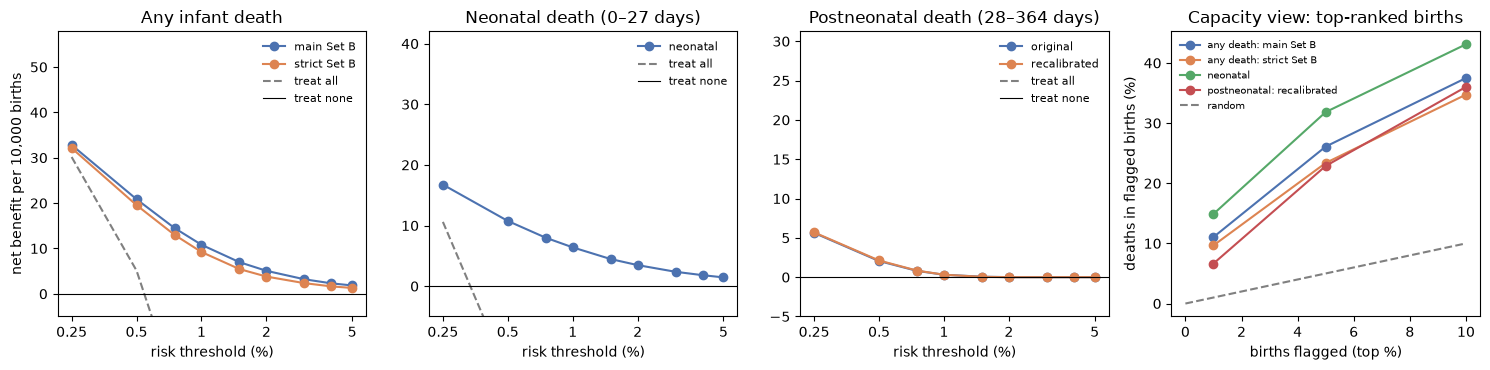

model,top_share,deaths_found_share,ppv_per_1000
str,f64,f64,f64
"""any death: main Set B""",0.0100,0.1104,60.8368
"""any death: main Set B""",0.0500,0.2610,28.7482
"""any death: main Set B""",0.1000,0.3749,20.6518
"""any death: strict Set B""",0.0100,0.0966,53.2098
"""any death: strict Set B""",0.0500,0.2338,25.7525
"""any death: strict Set B""",0.1000,0.3474,19.1347
"""neonatal""",0.0100,0.1489,52.9758
"""neonatal""",0.0500,0.3183,22.6494
"""neonatal""",0.1000,0.4310,15.3336


In [17]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
panels = [["any death: main Set B", "any death: strict Set B"], ["neonatal"], ["postneonatal: original", "postneonatal: recalibrated"]]
for ax, models in zip(axes, panels):
    for mname, col in zip(models, ["#4C72B0", "#DD8452"]):
        d = dca.filter(pl.col("model") == mname)
        ax.plot(100 * d["threshold"], 1e4 * d["net_benefit"], "o-", color=col, label=mname.split(": ")[-1])
    ax.plot(100 * d["threshold"], 1e4 * d["treat_all"].clip(lower_bound=-5), color="grey", ls="--", label="treat all")
    ax.axhline(0, color="black", lw=0.8, label="treat none")
    ax.set_xscale("log"); ax.set_xlabel("risk threshold (%)"); ax.set_ylim(-5, None)
    ax.set_xticks([0.25, 0.5, 1, 2, 5]); ax.minorticks_off()
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_title({"any death": "Any infant death", "neonatal": "Neonatal death (0–27 days)",
                  "postneonatal": "Postneonatal death (28–364 days)"}[models[0].split(":")[0]])
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("net benefit per 10,000 births")
# capacity view: deaths found per 10,000 births when the top 1, 5 or 10% are flagged
cap = []
for name, d in pred.group_by("model", maintain_order=True):
    y = d.sort("p", descending=True)["y"].to_numpy()
    for share in (0.01, 0.05, 0.10):
        k = int(share * len(y))
        cap.append({"model": name[0], "top_share": share, "deaths_found_share": y[:k].sum() / y.sum(), "ppv_per_1000": 1000 * y[:k].mean()})
cap = pl.DataFrame(cap)
cap.write_csv(REPORTS / "extra_capacity.csv")
for mname, col in zip(["any death: main Set B", "any death: strict Set B", "neonatal", "postneonatal: recalibrated"],
                      ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]):
    d = cap.filter(pl.col("model") == mname)
    axes[3].plot(100 * d["top_share"], 100 * d["deaths_found_share"], "o-", color=col, label=mname)
axes[3].plot([0, 10], [0, 10], color="grey", ls="--", label="random")
axes[3].set_xlabel("births flagged (top %)"); axes[3].set_ylabel("deaths in flagged births (%)")
axes[3].set_title("Capacity view: top-ranked births"); axes[3].legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "extra_decision_curves.png", dpi=150); plt.show()
cap

**Result.** If a program can contact only the top 10% of births, those births contain 37.5% of infant deaths (main model), 34.7% (strict), 43.1% of neonatal deaths (neonatal model) and 36.0% of postneonatal deaths (postneonatal model). Recalibration does not change these shares, because it does not change the order of the births.

## 9. Post-hoc audit: mediation with the obstetric gestational age (25 Nov 2026; GitHub issues #1 and #3)

**Why.**
- **#3.** Section 7 uses the combined gestation `COMBGEST`, which NCHS replaced by the obstetric estimate `OEGest_Comb` in 2014; 24% of singletons change gestational-age class between the two (`04_association` section 19).
- **#1.** The mediation split assumes no unmeasured confounder of gestational age and death. The collider demonstration (`04_association` section 14) shows that such confounding exists: with gestational age in the model, hypertension looks protective (RR 0.90). A direct-effect RR below 1, and a proportion mediated above 1, are what this bias produces. So the proportions mediated are **upper bounds** for the share that runs through earlier delivery, not exact shares.

**What.** Section 7 refitted for hypertension, diabetes and smoking with gestational-age classes from `OEGest_Comb` (analysis table from `04_association` section 19), 200 bootstrap replicates.

**Rule fixed before the run.** Reported next to section 7; the pre-set expectations (hypertension > 0.5, smoking < 0.5) are judged again on these numbers.

In [18]:
AUDIT_P2 = ROOT / "data" / "part2" / "births_audit.parquet"    # built in 04_association section 19
MED_OE_FILE = REPORTS / "extra_mediation_oe.csv"
if REBUILD or not MED_OE_FILE.exists():
    rows, boot = [], []
    for e in [x for x in p2.EXPOSURES if x.name in ("hypertension", "diabetes", "smoking")]:
        M = Mediation(e, src=AUDIT_P2, ga_col="ga_oe")
        n0, d0 = M.g["n"].to_numpy(), M.g["d"].to_numpy()
        cpat, W, beta = M.fit(n0, d0)
        rows += [{"exposure": e.name, **r} for r in M.effects(cpat, W, beta)]
        rng = np.random.default_rng([SEED, 99, len(rows)])
        t0 = time.time()
        for b in range(BOOT_MED):
            dd = rng.poisson(d0)
            nn = rng.poisson(n0 - d0) + dd
            cp, Wb, bb = M.fit(nn, dd, warm=(W, beta))
            boot += [{"exposure": e.name, "rep": b, **r} for r in M.effects(cp, Wb, bb)]
            if b % 25 == 0:
                log(e.name, "OE bootstrap", b, f"{time.time() - t0:.0f}s")
        del M, cpat
        gc.collect()
    est = pl.DataFrame(rows)
    ci = pl.DataFrame(boot).group_by("exposure", "label").agg(
        [pl.col(c).quantile(q, "linear").alias(f"{c}_{s}") for c in ("nde_rr", "prop_mediated")
         for q, s in ((0.025, "lo"), (0.975, "hi"))])
    est.join(ci, on=["exposure", "label"], how="left").write_csv(MED_OE_FILE)
med_oe = pl.read_csv(MED_OE_FILE)
med_oe.select("exposure", "label", "te_rr", "nde_rr", "nde_rr_lo", "nde_rr_hi", "prop_mediated", "prop_mediated_lo", "prop_mediated_hi").join(
    med.select("exposure", "label", pl.col("nde_rr").alias("nde_rr_combgest"), pl.col("prop_mediated").alias("prop_mediated_combgest")),
    on=["exposure", "label"])

12:37:09 hypertension OE bootstrap 0 3s


12:38:08 hypertension OE bootstrap 25 62s


12:39:08 hypertension OE bootstrap 50 122s


12:40:09 hypertension OE bootstrap 75 183s


12:41:09 hypertension OE bootstrap 100 243s


12:42:08 hypertension OE bootstrap 125 301s


... (15 outputs left out)

12:53:31 smoking OE bootstrap 125 42s


12:53:39 smoking OE bootstrap 150 51s


12:53:48 smoking OE bootstrap 175 59s


exposure,label,te_rr,nde_rr,nde_rr_lo,nde_rr_hi,prop_mediated,prop_mediated_lo,prop_mediated_hi,nde_rr_combgest,prop_mediated_combgest
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""hypertension""","""yes""",1.4894,0.9214,0.8959,0.9492,1.1607,1.0977,1.2226,0.9835,1.0325
"""diabetes""","""yes""",1.7842,1.0963,1.0513,1.1279,0.8772,0.8462,0.9305,1.2636,0.6731
"""smoking""","""any""",1.6703,1.4323,1.4082,1.4527,0.3550,0.3409,0.3685,1.4352,0.3559


**Result.**

| Exposure | Proportion mediated, `COMBGEST` (section 7) | Proportion mediated, obstetric estimate | Direct-effect RR, obstetric estimate |
|---|---|---|---|
| Hypertension | 1.03 (0.97–1.09) | **1.16 (1.10–1.22)** | **0.92 (0.90–0.95)** |
| Diabetes | 0.67 (0.63–0.72) | 0.88 (0.85–0.93) | 1.10 (1.05–1.13) |
| Smoking | 0.36 (0.34–0.37) | 0.36 (0.34–0.37) | 1.43 (1.41–1.45) |

- **The split depends on the gestational-age measure.** With the more accurate obstetric estimate, more of the hypertension and diabetes effects seem to run through gestational age. Smoking does not change.
- **Hypertension now has a direct-effect RR clearly below 1.** Pre-pregnancy hypertension cannot plausibly *protect* a baby once gestational age is held fixed. This is the signature of unmeasured gestational-age–death confounding (the collider bias of `04_association` section 14), and it grows when gestational age is measured better.
- **Conclusion (#1).** The proportions mediated are **upper bounds** for the share of each effect that runs through earlier delivery, not exact shares. The robust statements are qualitative: most of the hypertension and diabetes effects run through earlier delivery, and most of the smoking effect does not (it fits SUID). The pre-set expectations still hold (hypertension lower limit 1.10 > 0.5; smoking upper limit 0.37 < 0.5), but they are judged on biased quantities. The total effects do not depend on this assumption.

## Summary

All analyses are post-hoc, with rules fixed in the plan before each run (change log 25 Nov 2026).

| # | Question | Result |
|---|---|---|
| E6 | BMI data vs NVSR 69(9) | **PASS**: births identical, rates within 1.1% |
| E1 | Cause of death | Diabetes → anomalies **holds** (ratio 1.58); smoking → SUID **holds** (1.80); hypertension → P07 **fails** (0.95) |
| E2 | Recording errors | All RRs **robust**; non-differential errors mean our RRs are probably too low |
| E3 | Stillbirths | Diabetes **biased** by live-birth selection: 1.84 → 2.48 with fetal deaths; hypertension 1.50 → 1.74 |
| E4 | Mediation | Upper bounds (section 9): most of the hypertension (1.03) and diabetes (0.67) effects run through earlier delivery; smoking only one third (SUID) |
| E5 | Decision curves | Main, strict and neonatal models useful at 0.25–5%; postneonatal useful only at low thresholds |

- **What it adds to the thesis.** The factors act through *specific* causes that fit their biology (diabetes → birth defects, smoking → SUID, hypertension → earlier delivery). This is evidence that a social confounder alone cannot give. The Part 2 RRs for diabetes and hypertension are probably **too low**, because of recording errors and because stillbirths are left out.
- **Limits.** The diabetes recording priors are assumptions. Fetal-death records miss 8–15% of the items. The direct and indirect effects assume no unmeasured confounder of gestational age and death.
- **Not done.** The interval could not be analysed with stillbirths (no item on the fetal file). CDC WONDER was not used; NVSR 69(9) is the external check.